# $navsim$数据的存储结构 

**navsim数据集的文件框架（这里是保存在了Udata大文件夹下）** 
- G:\Udata
  - navsim_exp\  # 实验结果（**只有运行完训练py文件才会生成**）
  - openscene-v1.1\
    - navsim_logs\（**navsim_logs = 对驾驶场景的结构化记录和标注**）
      - mini\ # 原始场景日志
      - test
    - sensor_blobs\(**sensor_blobs = 车辆看到的环境**)
      - mini\ # 原始传感器数据
      - test

## 1. navsim_logs：场景日志与标注数据

### （1）目录里的详细数据结构

你的目录：
G:\Udata\navsim_logs\mini\
├── 2021.05.12.22.00.38_veh-35_01008_01518.pkl\
├── 2021.05.12.22.28.35_veh-35_00620_01164.pkl\
└── ...


每个 .pkl 文件通常对应一段驾驶场景，内部包含多个时间帧的信息。

| 数据类型 | 具体内容 | 作用 |
| ---- | ---- | ---- |
| 自车状态 | 位置、速度、加速度、航向角等 | 知道车辆当前如何运动 |
| 历史轨迹 | 过去多个时刻的车辆位置 | 分析车辆之前的运动 |
| 未来轨迹 | 未来多个时刻的车辆位置 | 作为轨迹预测或规划的监督信息 |
| 环境标注 | 其他车辆、行人等交通参与者的信息 | 理解周围交通环境 |
| 场景信息 | 时间戳、场景标识、地图关联等 | 定位和组织数据 |
| 传感器索引 | 与传感器数据对应的标识或路径 | 查找对应的图像、点云 |

具体字段以 NAVSIM 版本和 .pkl 内部结构为准。这是为了说明数据含义而编写的示意结构，不是你实际 .pkl 文件的字段定义。

想要查看pkl文件当中的数据是什么样的：\
**1)我们先导出第一条记录，以json的形式展示**

In [ ]:
python -c "import pickle,json; p='/mnt/g/Udata/navsim_logs/mini/2021.05.12.22.00.38_veh-35_01008_01518.pkl'; d=pickle.load(open(p,'rb')); json.dump(d[0],open('/home/haha/navsim_first_frame.json','w',encoding='utf-8'),indent=4,ensure_ascii=False,default=str); print('转换完成')"

```python
import pickle,json;
p='/mnt/g/Udata/navsim_logs/mini/2021.05.12.22.00.38_veh-35_01008_01518.pkl'; 
d=pickle.load(open(p,'rb')); 
json.dump(d[0],open('/home/haha/navsim_first_frame.json','w',encoding='utf-8'),indent=4,ensure_ascii=False,default=str); 
print('转换完成')
```

**2)查看这个pkl文件一共有多少帧**

In [ ]:
python -c "import pickle; p='/mnt/g/Udata/navsim_logs/mini/2021.05.12.22.00.38_veh-35_01008_01518.pkl'; d=pickle.load(open(p,'rb')); print('总记录数:',len(d)); print('第一帧:',d[0]['frame_idx']); print('最后一帧:',d[-1]['frame_idx'])"

```python
import pickle; 
p='/mnt/g/Udata/navsim_logs/mini/2021.05.12.22.00.38_veh-35_01008_01518.pkl';
d=pickle.load(open(p,'rb'));
print('总记录数:',len(d)); 
print('第一帧:',d[0]['frame_idx']); 
print('最后一帧:',d[-1]['frame_idx'])
```

**3)查看场景数，场景记录数**

In [ ]:
python -c "import pickle,collections; p='/mnt/g/Udata/navsim_logs/mini/2021.05.12.22.00.38_veh-35_01008_01518.pkl'; d=pickle.load(open(p,'rb')); c=collections.Counter(x['scene_name'] for x in d); print('场景数量:',len(c)); print('各场景记录数:',c)"

```python
import pickle,collections;
p='/mnt/g/Udata/navsim_logs/mini/2021.05.12.22.00.38_veh-35_01008_01518.pkl';
d=pickle.load(open(p,'rb'));
c=collections.Counter(x['scene_name'] for x in d);
print('场景数量:',len(c));
print('各场景记录数:',c)
```

4）里面数据结构：
| 概念 | 含义 | 你的数据 |
| ---- | ---- | ---- |
| 场景数 | 一段驾驶日志被划分成多少个场景 | 26 个 |
| 记录数 | PKL 列表中保存多少条数据 | 1020 条 |
| 帧数 | 每个场景包含多少个时间点的数据帧 | 24、40 或 36 帧 |

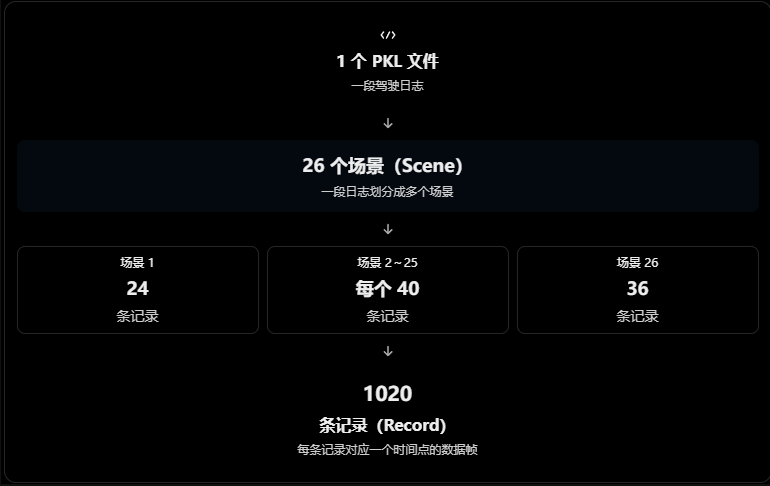

**5).pkl内部具体代码：**
```python
#其中navsim数据集中navsim_log数据文件中的pkl文件（这里用json来打开），只展示了第一帧的数据
#这里对照nusence那个数据集学习，这里相当于是一个sample
[
    {
        "token": "1a11259978a256cd",
        "frame_idx": 0,
        "timestamp": 1620857889701076,
        "log_name": "2021.05.12.22.00.38_veh-35_01008_01518",
        "log_token": "d908a069f1135360",
        "scene_name": "log-0001-scene-0001",
        "scene_token": "165060762e765a5a",
        "map_location": "us-nv-las-vegas-strip",
        "roadblock_ids": [
            "66034",
            "66749",...]
        "vehicle_name": "veh-35",
        "can_bus": "[ 6.64654120e+05  3.99926403e+06  6.06461371e+02  5.24707638e-01\n  5.97052982e-03 -1.23610885e-02 -8.51171810e-01 -1.35724032e+00\n  1.11431389e-02 -6.91697580e-02  4.35508025e+00 -6.31641440e-02\n -3.10592044e-02 -3.35391508e-03 -4.14308671e-03 -1.32776670e-03\n  0.00000000e+00  0.00000000e+00]",
        "lidar_path": "2021.05.12.22.00.38_veh-35_01008_01518/MergedPointCloud/1a11259978a256cd.pcd",
        "lidar2ego_translation": "[0 0 0]",
        "lidar2ego_rotation": [
            1.0,
            0.0,
            0.0,
            0.0
        ],
        "ego2global_translation": "[6.64654120e+05 3.99926403e+06 6.06461371e+02]",
        "ego2global_rotation": "[ 0.52470764  0.00597053 -0.01236109 -0.85117181]",
        "ego_dynamic_state": [
            4.35508025275723,
            -0.06316414400672618,
            -1.3572403213129705,
            0.011143138862639167
        ],
        "traffic_lights": [
            [
                64003,
                true
            ],
            [
                68965,
                true
            ]]
        "driving_command": "[0 1 0 0]",
        "cams": {
            "CAM_F0": {
                "data_path": "2021.05.12.22.00.38_veh-35_01008_01518/CAM_F0/ed564f55883d50d3.jpg",
                "sensor2lidar_rotation": "[[ 0.00309581 -0.0252709   0.99967585]\n [-0.99995684 -0.00883471  0.00287334]\n [ 0.00875923 -0.9996416  -0.02529716]]",
                "sensor2lidar_translation": "[ 1.6701001  -0.02587495  1.5226235 ]",
                "cam_intrinsic": "[[1.545e+03 0.000e+00 9.600e+02]\n [0.000e+00 1.545e+03 5.600e+02]\n [0.000e+00 0.000e+00 1.000e+00]]",
                "distortion": "[-0.356123  0.172545 -0.00213   0.000464 -0.05231 ]"
            },
            "CAM_L0": {
                "data_path": "2021.05.12.22.00.38_veh-35_01008_01518/CAM_L0/8c30cd489a2d51e4.jpg",
                "sensor2lidar_rotation": "[[ 0.82089205  0.00592469  0.57105266]\n [-0.57091602 -0.01569342  0.82085846]\n [ 0.0138251  -0.9998593  -0.0095001 ]]",
                "sensor2lidar_translation": "[1.64635422 0.14336934 1.52146865]",
                "cam_intrinsic": "[[1.545e+03 0.000e+00 9.600e+02]\n [0.000e+00 1.545e+03 5.600e+02]\n [0.000e+00 0.000e+00 1.000e+00]]",
                "distortion": "[-0.356123  0.172545 -0.00213   0.000464 -0.05231 ]"
            },...] #8个摄像机
            'sample_prev',
            'sample_next',
            'ego2global',
            'lidar2ego',
            'lidar2global',
            'anns',
            'gt_boxes',
            'gt_names',
            'gt_velocity_3d',
            'instance_tokens'：
            "track_tokens":
             "occ_gt_final_path": "dataset/openscene-v1.0/occupancy/mini/log-0001-scene-0001/occ_gt/000_occ_final.npy",
        "flow_gt_final_path": "dataset/openscene-v1.0/occupancy/mini/log-0001-scene-0001/occ_gt/000_occ_final.npy"
    }
"anns": {
    "gt_boxes": [...],       # gt_boxes：目标的三维边界框，作用：描述目标的位置、尺寸和朝向 
    "gt_names": [...],       # gt_names：目标类别，作用： 区分车辆、行人、交通锥等 
    "gt_velocity_3d": [...], # gt_velocity_3d：目标三维速度，作用：描述目标的运动状态
    "instance_tokens": [...] #  instance_tokens：目标实例 ID，作用：标识具体是哪一个目标 
}
```

- track_tokens：标识和跟踪周围的物体。

  - 例如，自动驾驶汽车在连续三帧中都观察到同一辆汽车：即使汽车的位置不断变化，只要它是同一个被跟踪的目标，其跟踪标识通常保持一致。
它和 instance_tokens 的区别需要结合 OpenScene 的具体定义确认，不能仅凭名称认定两者完全相同。



- occ_gt_final_path：保存三维空间占据真值的文件路径<span style="color:red">哪里有物体</span>

  简单来说，就是把车辆周围的三维空间划分成许多小方格（Voxel，体素），判断哪些位置被物体占据。



- flow_gt_final_path：保存场景流动真值的文件路径<span style="color:red">物体怎么运动</span>

## 2. sensor_blobs：原始传感器数据（**sensor_blobs = 车辆看到的环境**）

你的目录：
G:\Udata\openscene-v1.1\sensor_blobs\mini\
├── 2021.05.12.22.00.38_veh-35_01008_01518\
├── 2021.05.12.22.28.35_veh-35_00620_01164\
└── ...


这里的每个场景文件夹与 navsim_logs 中同名的 .pkl 文件相对应。

主要保存：


- 摄像头图像（Camera）：记录车辆前方、侧方等方向的道路画面，用于识别车道线、车辆、行人、交通信号灯等。












- 激光雷达点云（LiDAR）：记录周围环境的三维空间信息，用于感知物体的位置、距离和几何形状。



需要注意：传感器数据不一定全部以 .jpg 或 .bin 形式保存，具体文件格式要查看你下载的场景目录。

## 3、navsim_exp数据文件夹（**系统运行后产生的两个**）：
- navsim_feature:
  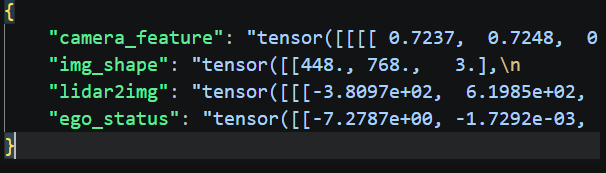
- navsim_target

# $run\_datase\_caching.py$  $and$  $run\_training\_metric\_caching.py$的区别 

## 1.对比

| 对比 | `run_dataset_caching.py` | `run_training_metric_caching.py` |
| --- | --- | --- |
| 主要任务 | 缓存模型训练数据 | 缓存训练评价指标 |
| 缓存内容 | Features、Targets | Metrics 或相关评分信息 |
| 主要用途 | 为神经网络提供输入和监督目标 | 为需要评价指标的训练方法提供预计算信息 |
| 核心函数 | 数据集缓存函数 | `cache_data()` |
| 是否所有模型都需要 | 取决于训练方式 | 取决于训练算法 |

## 2.相关基础知识

### （1）常见函数的导入：
**对应的python文件:**

```python
import logging          # python原生日志库
import hydra            # 配置管理框架，读取yaml、命令行覆写参数
from omegaconf import DictConfig  # Hydra配套，字典式配置对象，支持点访问 cfg.xxx

# nuplan 原生日志构建工具
from nuplan.planning.script.builders.logging_builder import build_logger
# NavSim：缓存主函数，预计算metric/特征并落地
from navsim.planning.metric_caching.train_caching import cache_data
# NavSim：构建并行worker（多进程/ray单节点）用来跑缓存任务
from navsim.planning.script.builders.worker_pool_builder import build_worker

logger = logging.getLogger(__name__) # 创建本文件的logger

CONFIG_PATH = "config/metric_caching"
CONFIG_NAME = "train_metric_caching"
#Hydra 会去 config/metric_caching/ 目录下加载 train_metric_caching.yaml
```
```python
@hydra.main(config_path=CONFIG_PATH, config_name=CONFIG_NAME, version_base=None)
def main(cfg: DictConfig) -> None:
```
- @hydra.main：Hydra 标准入口，自动解析 yaml + 命令行参数，组装成 cfg
- version_base=None：关闭 Hydra 版本校验（老项目常见写法）
- cfg：OmegaConf 字典，你可以在命令行覆盖参数，例如 worker=multiprocessing

### （2）/home/haha/iPad-main/navsim/planning/script/config/metric_caching/train_metric_caching.yaml配置文件详解
**相应的.yaml配置文件：**

```python
hydra:
  run:
    dir: ${output_dir}
  output_subdir: ${output_dir}/code/hydra           # Store hydra's config breakdown here for debugging
  searchpath:                                       # Only <exp_dir> in these paths are discoverable
    - pkg://navsim.planning.script.config.common    #告诉Hdray，当程序需要加载配置文件时，去哪里寻找其他配置文件
  job:
    chdir: False

defaults:
  - default_common
  - _self_

# Cache parameters
cache:
  cache_path:  ${oc.env:NAVSIM_EXP_ROOT}/train_metric_cache
  use_cache_without_dataset: false
  force_feature_computation: false

output_dir: ${cache.cache_path}/metadata
navsim_log_path: ${oc.env:OPENSCENE_DATA_ROOT}/navsim_logs/${train_test_split.data_split} # path to log annotations
```
| 参数 | 作用 | 数据类型 |
| ---- | ---- | -------- |
| `navsim_log_path` | 原始数据的读取路径 | 输入 |
| `cache.cache_path` | 缓存数据的保存路径 | 输出 |
| `output_dir` | 程序运行记录的保存路径 | 输出 |
|`hydra.searchpath：`| 配置文件搜索路径 | 输入 |


**\${train_test_split.data_split}**：读取 Hydra 配置中的 train_test_split 下面的 data_split

# 权重$checkpoint\_path$相关要点

## 1.什么时候用

- 想要从头开始完整的训练，需要先不要给$checkpoint\_path$赋值，之后当评估模型的时候（python navsim/planing/script/run_create_submission_pickle.py）才需要赋值。
- 运行训练模型时（python navsim/planing/script/run_training.py）需要将$checkpoint\_path$赋值为空：
  ```python
  checkpoint_path:''
  ```

## 2.用哪个权重（自己的or作者的）

- 用作者的在README中提供的链接进行下载相应的$.ckpt$文件
- 用自己的，在运行训练的代码（python navsim/planing/script/run_create_submission_pickle.py）后，终端会输出：
  ```python
  [2026-11-07 15:04:25,881][__main__][INFO] - Path where all results are stored: /mnt/g/Udata/navsim_exp/ke/navsim/11.07_15.04
  ```
  **重点看：** Path where all results are stored:翻译过来就是：所有运行结果保存的位置。
  因此，自己训练模型后的权重位置就是：
  ```python
  /mnt/g/Udata/navsim_exp/ke/navsim/11.07_15.04
  ```